In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
import joblib

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
df=pd.read_csv("../dataset/train.csv")

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
print(df.shape)

(891, 12)


In [5]:
print(df.columns.tolist())

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [7]:
missing=df.isnull().sum()
missing_df=pd.DataFrame({'Missing Values':missing,'Percentage':(missing/len(df)*100)}
                        )
missing_df

,Missing Values,Percentage
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
Age,177,19.865320
SibSp,0,0.000000
Parch,0,0.000000
Ticket,0,0.000000
Fare,0,0.000000


In [8]:
survival_count = df['Survived'].value_counts()

print("Survival Count:")
print(survival_count)

print("\nSurvival Percentage:")
print(df['Survived'].value_counts(normalize=True) * 100)

Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentage:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


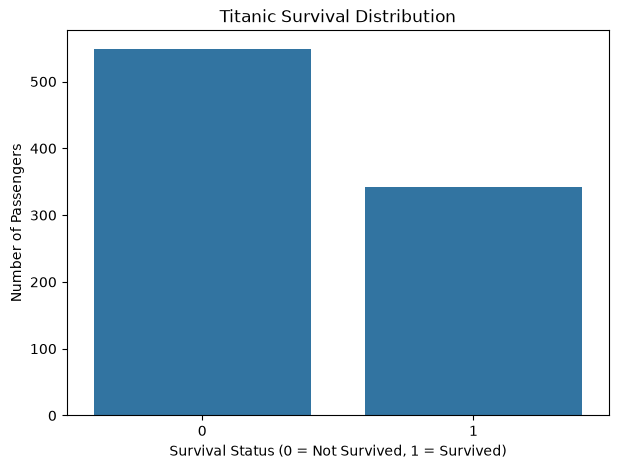

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Survived')

plt.title("Titanic Survival Distribution")
plt.xlabel("Survival Status (0 = Not Survived, 1 = Survived)")
plt.ylabel("Number of Passengers")

plt.show()

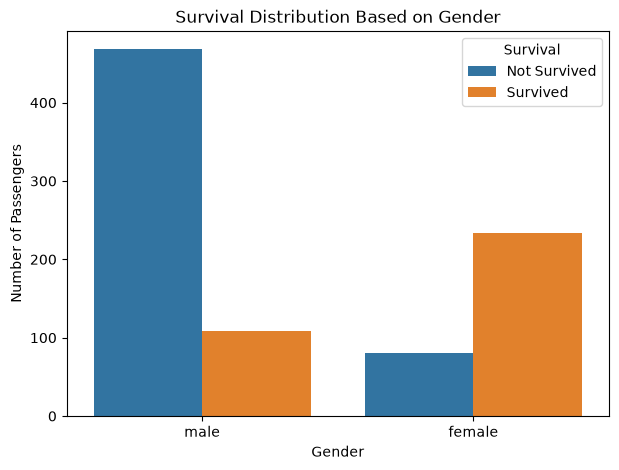

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Sex', hue='Survived')

plt.title("Survival Distribution Based on Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.legend(title="Survival", labels=["Not Survived", "Survived"])

plt.show()

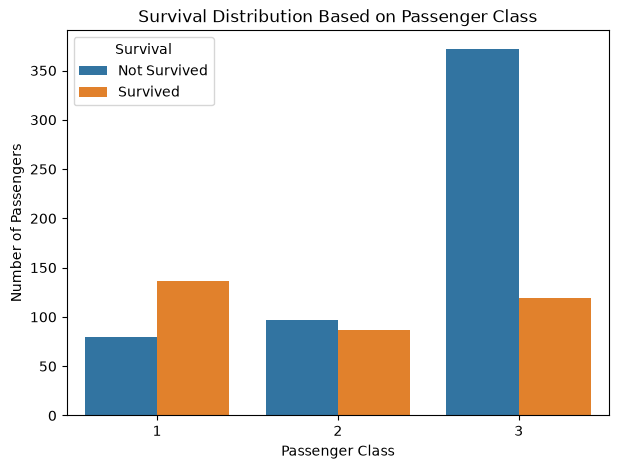

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Pclass', hue='Survived')

plt.title("Survival Distribution Based on Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.legend(title="Survival", labels=["Not Survived", "Survived"])

plt.show()

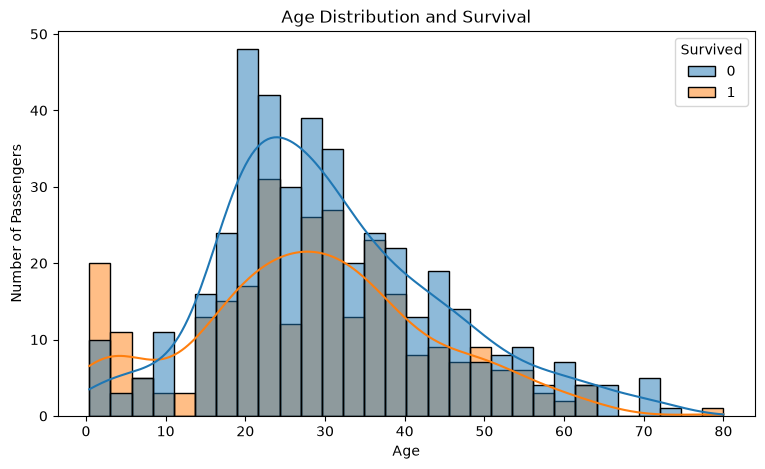

In [12]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Age',
    hue='Survived',
    bins=30,
    kde=True
)

plt.title("Age Distribution and Survival")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

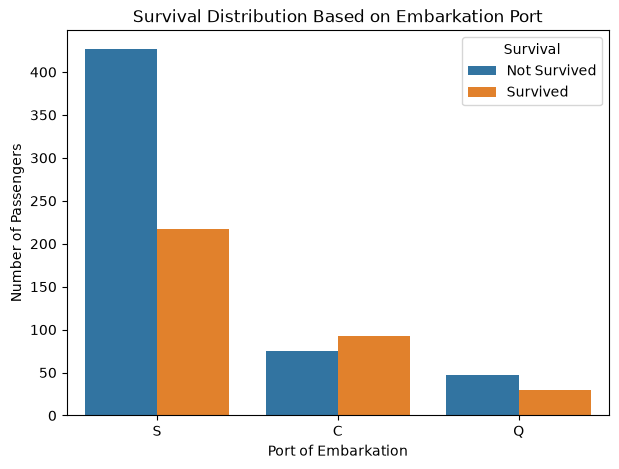

In [13]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='Embarked', hue='Survived')

plt.title("Survival Distribution Based on Embarkation Port")
plt.xlabel("Port of Embarkation")
plt.ylabel("Number of Passengers")

plt.legend(title="Survival", labels=["Not Survived", "Survived"])

plt.show()

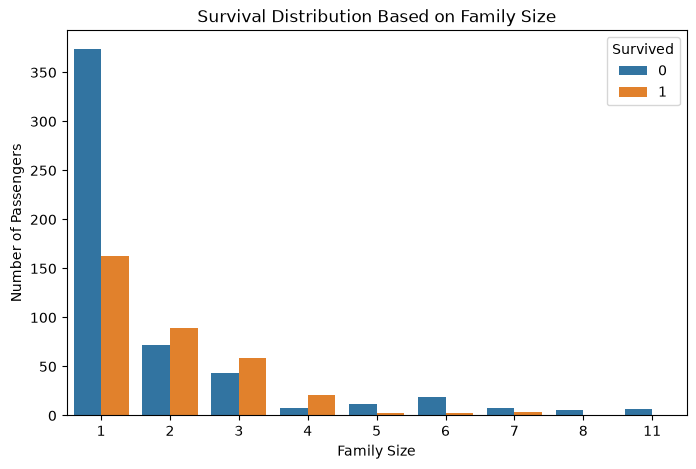

In [14]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

plt.figure(figsize=(8,5))

sns.countplot(data=df, x='FamilySize', hue='Survived')

plt.title("Survival Distribution Based on Family Size")
plt.xlabel("Family Size")
plt.ylabel("Number of Passengers")

plt.show()

In [15]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import joblib
import warnings

warnings.filterwarnings('ignore')

In [16]:
# Create a copy of the original dataset
data = df.copy()

# Feature engineering
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1

data['IsAlone'] = (data['FamilySize'] == 1).astype(int)

# Select input features
X = data[
    [
        'Pclass',
        'Sex',
        'Age',
        'SibSp',
        'Parch',
        'Fare',
        'Embarked',
        'FamilySize',
        'IsAlone'
    ]
]

# Target variable
y = data['Survived']

print("Features prepared successfully!")
print("X Shape:", X.shape)
print("y Shape:", y.shape)

Features prepared successfully!
X Shape: (891, 9)
y Shape: (891,)


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 712
Testing samples: 179


In [18]:
numeric_features = [
    'Age',
    'Fare',
    'SibSp',
    'Parch',
    'FamilySize',
    'Pclass',
    'IsAlone'
]

categorical_features = ['Sex', 'Embarked']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

In [19]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    by='Accuracy',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.804469,0.783333,0.681159,0.728682
2,Random Forest,0.804469,0.774194,0.695652,0.732824
1,Decision Tree,0.770950,0.725806,0.652174,0.687023


In [20]:
best_model_name = max(
    trained_models,
    key=lambda name: accuracy_score(
        y_test,
        trained_models[name].predict(X_test)
    )
)

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

y_pred = best_model.predict(X_test)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



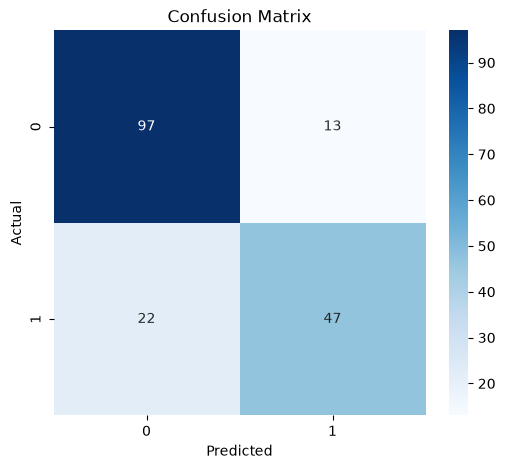

In [21]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()


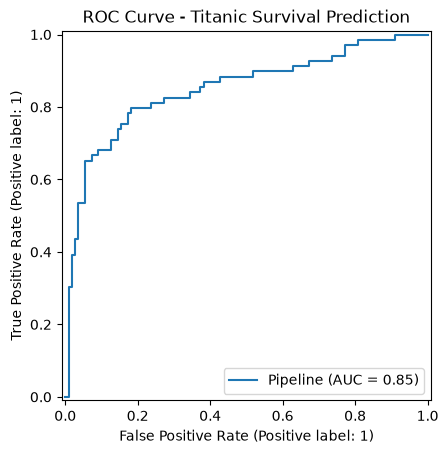

In [23]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(best_model, X_test, y_test)

plt.title("ROC Curve - Titanic Survival Prediction")
plt.show()

In [24]:
joblib.dump(best_model, '../backend/titanic_model.pkl')

print("Model saved successfully!")

Model saved successfully!
